In [3]:
%pip install pandas matplotlib seaborn

  Using cached pandas-3.1.1-cp315-cp315-win_amd64.whl.metadata (16 kB)
  Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp315-cp315-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.1.1-cp315-cp315-win_amd64.whl (10.9 MB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -----------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\aayushmaan\OneDrive\Desktop\hcl project\gold_rates_10_years_every_month.csv", encoding="cp1252")
df.head()

,10-Year Monthly Gold Rate Database in India (Oct 2016 – Nov 2026),Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8
0,Standard / 24K Gold Rates (? per 1g & 10g) wit...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,S.No.,Month & Year,Gold Rate / 1g (?),Gold Rate / 10g (?),MoM Change (?),MoM Profit / Loss (%),MoM Status,Cumulative Return vs Oct 2016 (%),Data Source
3,1,October 2016,"?3,007.14","?30,071.37",?0.00,0.00%,Baseline,0.00%,RBI Handbook
4,2,November 2016,"?2,979.64","?29,796.43",-?274.94,-0.91%,Loss,-0.91%,RBI Handbook


Matplotlib is building the font cache; this may take a moment.


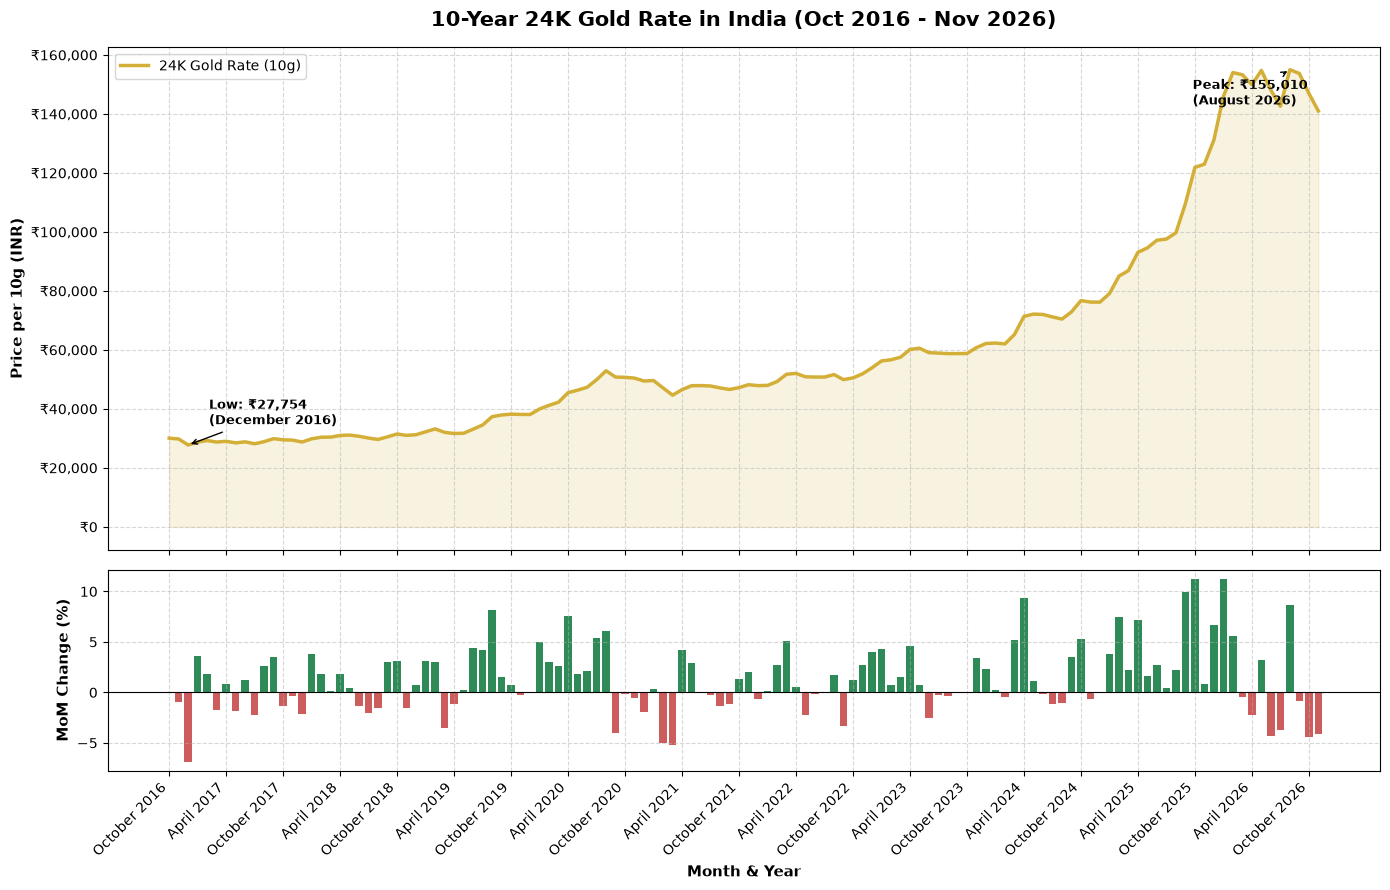

In [9]:
import glob
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

# Extract the first matching filename string from the list
matched_files = glob.glob('gold_rates_10_years*.csv')
file_path = (
    matched_files[0] if matched_files else 'gold_rates_10_years_every_month.csv'
)

# Load your CSV file using latin1 encoding to handle special currency symbols
df = pd.read_csv(file_path, skiprows=3, encoding='latin1')

# Keep only the 122 monthly records (exclude the summary statistics at the bottom)
df = df[pd.to_numeric(df['S.No.'], errors='coerce').notnull()].copy()


# Clean currency and percentage strings into numeric values
def clean_numeric(series):
  return (
      series.astype(str)
      .str.replace(r'[^0-9.-]', '', regex=True)
      .str.strip()
      .astype(float)
  )


# Automatically select the 10g price and MoM % columns by their position (columns 3 and 5)
df['Rate_10g'] = clean_numeric(df.iloc[:, 3])
df['MoM_Pct'] = clean_numeric(df.iloc[:, 5])
df['Date_Label'] = df.iloc[:, 1].astype(str).str.replace(' (MTD)', '', regex=False)

# Create a two-panel figure
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [2.5, 1]}, sharex=True
)
fig.patch.set_facecolor('white')

# --- Top Panel: 10g Gold Price Trend ---
ax1.plot(
    df['Date_Label'],
    df['Rate_10g'],
    color='#D4AF37',
    linewidth=2.5,
    label='24K Gold Rate (10g)',
)
ax1.fill_between(df['Date_Label'], df['Rate_10g'], color='#D4AF37', alpha=0.15)

# Highlight the 10-year peak and lowest points
max_idx = df['Rate_10g'].idxmax()
min_idx = df['Rate_10g'].idxmin()

ax1.annotate(
    f"Peak: ₹{df.loc[max_idx, 'Rate_10g']:,.0f}\n({df.loc[max_idx, 'Date_Label']})",
    xy=(max_idx, df.loc[max_idx, 'Rate_10g']),
    xytext=(-70, -25),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='black'),
    fontweight='bold',
    fontsize=9,
)

ax1.annotate(
    f"Low: ₹{df.loc[min_idx, 'Rate_10g']:,.0f}\n({df.loc[min_idx, 'Date_Label']})",
    xy=(min_idx, df.loc[min_idx, 'Rate_10g']),
    xytext=(15, 15),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='black'),
    fontweight='bold',
    fontsize=9,
)

ax1.set_title(
    '10-Year 24K Gold Rate in India (Oct 2016 - Nov 2026)',
    fontsize=15,
    fontweight='bold',
    pad=15,
)
ax1.set_ylabel('Price per 10g (INR)', fontsize=11, fontweight='bold')
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter('₹{x:,.0f}'))
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# --- Bottom Panel: Month-over-Month (MoM) % Change ---
colors = ['#2E8B57' if val >= 0 else '#CD5C5C' for val in df['MoM_Pct']]
ax2.bar(df['Date_Label'], df['MoM_Pct'], color=colors, width=0.8)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_ylabel('MoM Change (%)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Month & Year', fontsize=11, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

# Show every 6th month on the X-axis to prevent overlapping labels
tick_positions = range(0, len(df), 6)
ax2.set_xticks(tick_positions)
ax2.set_xticklabels(df['Date_Label'].iloc[tick_positions], rotation=45, ha='right')

plt.tight_layout()
plt.savefig('gold_rate_10yr_chart.png', dpi=300)
plt.show()


In [10]:
import glob
import pandas as pd

# Extract the first matching filename string from the list
matched_files = glob.glob('gold_rates_10_years*.csv')
file_path = (
    matched_files[0] if matched_files else 'gold_rates_10_years_every_month.csv'
)

# Load your CSV file using latin1 encoding
df = pd.read_csv(file_path, skiprows=3, encoding='latin1')

# Keep only the 122 monthly records (exclude the summary rows at the bottom)
df = df[pd.to_numeric(df['S.No.'], errors='coerce').notnull()].copy()


# Clean currency and percentage strings into numeric values
def clean_numeric(series):
  return (
      series.astype(str)
      .str.replace(r'[^0-9.-]', '', regex=True)
      .str.strip()
      .astype(float)
  )


df['Date'] = df.iloc[:, 1].astype(str).str.strip()
df['Rate_1g'] = clean_numeric(df.iloc[:, 2])
df['Rate_10g'] = clean_numeric(df.iloc[:, 3])
df['MoM_Change'] = clean_numeric(df.iloc[:, 4])
df['MoM_Pct'] = clean_numeric(df.iloc[:, 5])
df['Cum_Return'] = clean_numeric(df.iloc[:, 7])

# Locate key milestone rows
min_row = df.loc[df['Rate_10g'].idxmin()]
max_row = df.loc[df['Rate_10g'].idxmax()]
best_gain_row = df.loc[df['MoM_Pct'].idxmax()]
worst_drop_row = df.loc[df['MoM_Pct'].idxmin()]
start_row = df.iloc[0]
end_row = df.iloc[-1]

# Count profit, loss, and baseline months (excluding the Oct 2016 baseline)
monthly_changes = df.iloc[1:]
profit_months = (monthly_changes['MoM_Pct'] > 0).sum()
loss_months = (monthly_changes['MoM_Pct'] < 0).sum()

# Print formatted summary report
print('=' * 55)
print('10-YEAR 24K GOLD RATE SUMMARY IN INDIA (OCT 2016 - NOV 2026)')
print('=' * 55)
print(f'Total Months Tracked      : {len(df)} months')
print(
    f"Starting Rate ({start_row['Date']}) : ₹{start_row['Rate_10g']:,.2f} / 10g"
    f" (₹{start_row['Rate_1g']:,.2f} / 1g)"
)
print(
    f"Latest Rate ({end_row['Date']})   : ₹{end_row['Rate_10g']:,.2f} / 10g"
    f" (₹{end_row['Rate_1g']:,.2f} / 1g)"
)
print(f"Overall Cumulative Return : +{end_row['Cum_Return']:.2f}%")
print('-' * 55)
print(
    f"Lowest Monthly Rate       : ₹{min_row['Rate_10g']:,.2f} / 10g"
    f" ({min_row['Date']})"
)
print(
    f"Highest Monthly Rate      : ₹{max_row['Rate_10g']:,.2f} / 10g"
    f" ({max_row['Date']})"
)
print(
    f"10-Year Average Rate      : ₹{df['Rate_10g'].mean():,.2f} / 10g"
    f" (₹{df['Rate_1g'].mean():,.2f} / 1g)"
)
print(f"10-Year Median Rate       : ₹{df['Rate_10g'].median():,.2f} / 10g")
print('-' * 55)
print(
    f"Best Single-Month Gain    : +{best_gain_row['MoM_Pct']:.2f}%"
    f" (+₹{best_gain_row['MoM_Change']:,.2f}) in {best_gain_row['Date']}"
)
print(
    f"Worst Single-Month Drop   : {worst_drop_row['MoM_Pct']:.2f}%"
    f" (-₹{abs(worst_drop_row['MoM_Change']):,.2f}) in {worst_drop_row['Date']}"
)
print(
    f'Profit vs. Loss Months    : {profit_months} Profit months |'
    f' {loss_months} Loss months'
)
print('=' * 55)

# Optional: Display standard pandas descriptive statistics table
print('\nStatistical Distribution (10g Rate & MoM %):')
print(df[['Rate_1g', 'Rate_10g', 'MoM_Pct', 'Cum_Return']].describe().round(2))


10-YEAR 24K GOLD RATE SUMMARY IN INDIA (OCT 2016 - NOV 2026)
Total Months Tracked      : 122 months
Starting Rate (October 2016) : ₹30,071.37 / 10g (₹3,007.14 / 1g)
Latest Rate (November 2026 (MTD))   : ₹140,990.00 / 10g (₹14,099.00 / 1g)
Overall Cumulative Return : +368.85%
-------------------------------------------------------
Lowest Monthly Rate       : ₹27,754.29 / 10g (December 2016)
Highest Monthly Rate      : ₹155,010.00 / 10g (August 2026)
10-Year Average Rate      : ₹60,563.05 / 10g (₹6,056.30 / 1g)
10-Year Median Rate       : ₹49,895.99 / 10g
-------------------------------------------------------
Best Single-Month Gain    : +11.26% (+₹14,775.35) in January 2026
Worst Single-Month Drop   : -6.85% (-₹2,042.14) in December 2016
Profit vs. Loss Months    : 75 Profit months | 46 Loss months

Statistical Distribution (10g Rate & MoM %):
        Rate_1g   Rate_10g  MoM_Pct  Cum_Return
count    122.00     122.00   122.00      122.00
mean    6056.30   60563.05     1.33      101.40
s